<a href="https://colab.research.google.com/github/Hema392/ITA0314-Mobile-Computing-/blob/main/Exp_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


EXPERIMENT 18: ERLANG B

Blocking Probability (%)
E/m [5, 10, 15, 20, 25, 30]
2 [3.67, 0.004, 0.0, 0.0, 0.0, 0.0]
5 [28.487, 1.838, 0.016, 0.0, 0.0, 0.0]
10 [56.395, 21.458, 3.65, 0.187, 0.003, 0.0]
20 [76.436, 53.796, 33.0, 15.889, 5.022, 0.846]

Required channels for 2% GoS: 17


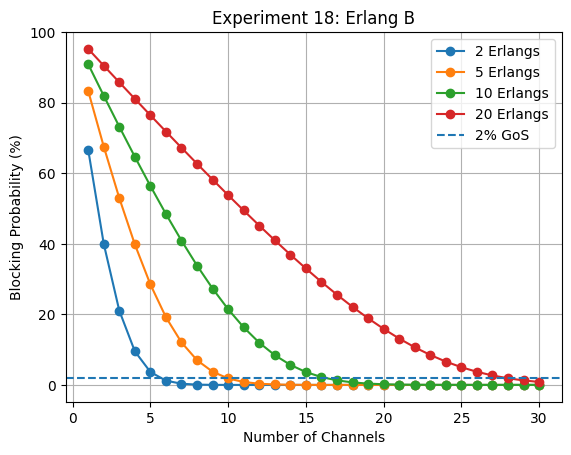

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
print("\nEXPERIMENT 18: ERLANG B")

def erlang_b(E, m):
    B = 1.0
    for k in range(1, m+1):
        B = (E*B)/(k + E*B)
    return B

loads = [2, 5, 10, 20]
channels = [5, 10, 15, 20, 25, 30]

print("\nBlocking Probability (%)")
print("E/m", channels)

for E in loads:
    values = [round(100*erlang_b(E,m),3)
              for m in channels]
    print(E, values)

E = 10
target = 0.02
m = 1

while erlang_b(E,m) > target:
    m += 1

print("\nRequired channels for 2% GoS:", m)

m_values = range(1,31)

plt.figure()
for E in loads:
    blocking = [100*erlang_b(E,m)
                for m in m_values]
    plt.plot(m_values, blocking, marker='o',
             label=f"{E} Erlangs")

plt.axhline(2, linestyle='--', label="2% GoS")
plt.xlabel("Number of Channels")
plt.ylabel("Blocking Probability (%)")
plt.title("Experiment 18: Erlang B")
plt.legend()
plt.grid()
plt.show()